**Objetivo:** Extraer, limpiar y evaluar 2.000.000 de pares de oraciones de alta calidad para el entrenamiento de un modelo de Traducción Automática.

**Límites de diseño:** Máximo 60 palabras por oración y un ratio de longitud controlado para optimizar las matrices de atención del modelo Transformer.

In [1]:
# Instalación de librerías críticas para el procesamiento
# pyarrow: Para leer archivos .parquet (NewsCommentary)
# fasttext: Modelo pre-entrenado de Meta para detección de idiomas
# openpyxl: Motor para escribir archivos Excel de múltiples hojas
# scikit-learn: Para el análisis de n-gramas en el EDA
%pip install -q pyarrow fasttext==0.9.3 openpyxl scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 2.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


**1. Descarga del Dataset Base (Kaggle):** Kaggle requiere autenticación para sus descargas. Utilizaremos la librería `kagglehub` para acceder directamente a los recursos sin necesidad de gestionar tokens manualmente.

In [2]:
!pip install -q kagglehub
import kagglehub

# Dataset "English-Spanish Translation Dataset" de Lonnie Qin
print("Conectando con Kaggle...")
ruta_kaggle = kagglehub.dataset_download("lonnieqin/englishspanish-translation-dataset")
print(f"El dataset se descargó exitosamente en el entorno: {ruta_kaggle}")

Conectando con Kaggle...


100%|██████████| 2.72M/2.72M [00:00<00:00, 41.8MB/s]

Extracting files...


El dataset se descargó exitosamente en el entorno: /root/.cache/kagglehub/datasets/lonnieqin/englishspanish-translation-dataset/versions/1


**2. Extracción Masiva, Filtrado y Deduplicación:** Este bloque procesa múltiples corpus masivos (Kaggle, TED2020, NewsCommentary y Europarl).
Para evitar desbordamientos de RAM (OOM - Out of Memory), la información se lee en flujos (streams) y se guarda temporalmente en una base de datos SQLite. Se aplican filtros de caracteres, longitud y detección estricta de idioma mediante FastText.

In [3]:
import csv, hashlib, html, io, json, re, sqlite3, tarfile, time, unicodedata
import urllib.request, zipfile, shutil
from collections import Counter
from pathlib import Path
from itertools import zip_longest

# Parámetros globales
TOTAL = 2_000_000         # Objetivo final de pares
SEED = 2026               # Semilla para aleatoriedad y hash
MIN_WORDS, MAX_WORDS = 2, 60  # Límite estricto de palabras
MAX_RATIO = 3.0           # Máxima diferencia de longitud permitida (ej. 1 palabra en EN y 4 en ES se rechaza)
LID_THRESHOLD = 0.60      # Confianza mínima del 60% para que FastText acepte el idioma

# Preparación de directorios
ROOT = Path('datos_traductor')
ROOT.mkdir(exist_ok=True)
CACHE = ROOT / 'descargas'
CACHE.mkdir(exist_ok=True)

# Catálogo de fuentes de datos
SOURCES = [
    dict(name='Kaggle_LonnieQin', kind='csv', raw=113322,
         url=f"{ruta_kaggle}/data.csv",
         page='https://www.kaggle.com/datasets/lonnieqin/englishspanish-translation-dataset',
         license='Kaggle'),
    dict(name='TED2020_v1', kind='zip', raw=416846,
         url='https://object.pouta.csc.fi/OPUS-TED2020/v1/moses/en-es.txt.zip',
         page='https://opus.nlpl.eu/datasets/TED2020',
         license='Consultar condiciones de TED y ficha OPUS'),
    dict(name='NewsCommentary_Helsinki', kind='parquet', raw=238872,
         url='https://huggingface.co/datasets/Helsinki-NLP/news_commentary/resolve/bbaf548083e788e0e6d2ca68efc325283fe2aff5/en-es/train-00000-of-00001.parquet',
         page='https://huggingface.co/datasets/Helsinki-NLP/news_commentary',
         license='Conservar procedencia y consultar fuente'),
    dict(name='Europarl_v7', kind='tgz', raw=1965734,
         url='https://www.statmt.org/europarl/v7/es-en.tgz',
         page='https://www.statmt.org/europarl/',
         license='Ver Terms of Use del corpus; citar Koehn (2005)'),
]

# Funciones de soporte
def download(url, path):
    """Descarga archivos remotos o copia archivos locales con reintentos automáticos."""
    if not url.startswith('http'):
        if Path(url).exists():
            shutil.copy(url, path)
            return path
        else:
            raise FileNotFoundError(f"Falta el archivo de Kaggle. Asegúrate de correr la celda anterior.")

    if path.exists(): return path

    tmp = path.with_suffix(path.suffix + '.part')
    for attempt in range(3):
        try:
            print('Descargando:', url, flush=True)
            with urllib.request.urlopen(url, timeout=120) as src, tmp.open('wb') as dst:
                while chunk := src.read(1024 * 1024):
                    dst.write(chunk)
            tmp.replace(path)
            return path
        except Exception:
            if attempt == 2: raise
            time.sleep(2 ** attempt)

# Hash de integridad para validar los archivos
def sha256_file(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        while chunk := f.read(1024 * 1024):
            h.update(chunk)
    return h.hexdigest()

# Iterador para que los archivos paralelos tengan el mismo número de líneas
def paired_lines(a, b):
    for i, (en, es) in enumerate(zip_longest(a, b), 1):
        if en is None or es is None:
            raise ValueError('Archivos con distinta cantidad de líneas; no se permite truncar.')
        yield str(i), en, es

# Lector universal para diferentes formatos de dataset
def rows(source, path):
    if source['kind'] == 'csv':
        with open(path, 'r', encoding='utf-8') as f:
            reader = csv.reader(f)
            next(reader, None) # Saltar cabecera
            for i, row in enumerate(reader):
                if len(row) >= 2:
                    yield str(i), row[0], row[1]
    elif source['kind'] == 'parquet':
        import pyarrow.parquet as pq
        for batch in pq.ParquetFile(path).iter_batches(batch_size=2048):
            for r in batch.to_pylist():
                yield str(r['id']), r['translation']['en'], r['translation']['es']
    elif source['kind'] == 'zip':
        with zipfile.ZipFile(path) as archive:
            ens = [x for x in archive.namelist() if x.endswith('.en')]
            ess = [x for x in archive.namelist() if x.endswith('.es')]
            assert len(ens) == len(ess) == 1, archive.namelist()
            with archive.open(ens[0]) as a, archive.open(ess[0]) as b:
                yield from paired_lines(io.TextIOWrapper(a, encoding='utf-8'),
                                        io.TextIOWrapper(b, encoding='utf-8'))
    else:
        with tarfile.open(path, 'r:gz') as archive:
            ens = [x for x in archive.getmembers() if x.isfile() and x.name.endswith('.en')]
            ess = [x for x in archive.getmembers() if x.isfile() and x.name.endswith('.es')]
            assert len(ens) == len(ess) == 1
            en_path, es_path = CACHE / 'europarl_v7.en', CACHE / 'europarl_v7.es'
            for member, dest in [(ens[0], en_path), (ess[0], es_path)]:
                if not dest.exists():
                    tmp = dest.with_suffix(dest.suffix + '.part')
                    with archive.extractfile(member) as src, tmp.open('wb') as out:
                        shutil.copyfileobj(src, out)
                    tmp.replace(dest)
        with en_path.open(encoding='utf-8') as a, es_path.open(encoding='utf-8') as b:
            yield from paired_lines(a, b)

# Normalizar el texto
def clean(text):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', html.unescape(text))).strip()

# Crea una clave única (Hash) por oración para eliminar duplicados luego
def digest(text):
    return hashlib.sha256(text.casefold().encode('utf-8')).digest()

# Filtro de primer nivel: longitud, ratio de palabras y limpieza de ruido (URLs y HTML)
def basic_filter(en, es):
    en, es = clean(en), clean(es)
    n, m = len(en.split()), len(es.split())
    if not (MIN_WORDS <= n <= MAX_WORDS and MIN_WORDS <= m <= MAX_WORDS):
        return None
    if max(n, m) / min(n, m) > MAX_RATIO or en.casefold() == es.casefold():
        return None
    if any('\ufffd' in s or re.search(r'<[^>]+>|https?://|www\.', s)
           or sum(c.isalpha() for c in s) / max(1, len(s)) < .45 for s in (en, es)):
        return None
    return en, es, n, m

# Motor principal
def build():
    import fasttext
    import importlib.metadata

    # Descargar modelo preentrenado para clasificar el idioma
    model_path = download('https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.bin', CACHE / 'lid.176.bin')
    lid = fasttext.load_model(str(model_path))

    run = ROOT / time.strftime('run_%Y%m%d_%H%M%S')
    run.mkdir(exist_ok=False)

    # Inicializar Base de Datos SQLite (Actúa como memoria RAM extendida)
    db = sqlite3.connect(run / 'candidatos.sqlite')
    db.execute('PRAGMA journal_mode=WAL')
    db.execute('PRAGMA cache_size=-64000')
    db.execute('CREATE TABLE pairs (en TEXT, es TEXT, source TEXT, original_id TEXT, en_len INT, es_len INT, en_key BLOB UNIQUE, es_key BLOB UNIQUE, rank BLOB)')

    report = dict(target=TOTAL, seed=SEED, min_words=MIN_WORDS, max_words=MAX_WORDS,
                  max_ratio=MAX_RATIO, language_threshold=LID_THRESHOLD,
                  language_model_sha256=sha256_file(model_path), sources=[],
                  packages={p: importlib.metadata.version(p) for p in ['pyarrow', 'fasttext']})
    try:
        for source in SOURCES:
            path = download(source['url'], CACHE / (source['name'] + '.' + source['kind']))
            stats = Counter()


            # Filtro de segundo nivel (Detección de idioma) e inserción en base de datos
            def ingest(batch):
                if not batch: return
                labels, probs = lid.predict([x[1] for x in batch] + [x[2] for x in batch], k=1)
                size = len(batch)
                values = []
                for i, (idx, en, es, n, m) in enumerate(batch):
                    # Rechazar si no confía en que sea inglés y español respectivamente
                    if (labels[i][0] != '__label__en' or labels[i+size][0] != '__label__es'
                            or min(probs[i][0], probs[i+size][0]) < LID_THRESHOLD):
                        stats['rejected_language'] += 1
                        continue
                    ek, sk = digest(en), digest(es)
                    rank = hashlib.sha256(str(SEED).encode() + ek + sk).digest()
                    values.append((en, es, source['name'], idx, n, m, ek, sk, rank))

                # Inserción ignorando colisiones (Deduplicación automática nativa de SQLite)
                before = db.total_changes
                db.executemany('INSERT OR IGNORE INTO pairs VALUES (?,?,?,?,?,?,?,?,?)', values)
                added = db.total_changes - before
                stats['accepted_unique'] += added
                stats['duplicate_either_side'] += len(values) - added
                db.commit()

            batch = []
            for idx, en, es in rows(source, path):
                stats['read'] += 1
                pair = basic_filter(en, es)
                if pair is None:
                    stats['rejected_basic'] += 1
                else:
                    batch.append((idx, *pair))
                if len(batch) >= 2048:
                    ingest(batch)
                    batch = []
                if stats['read'] % 100000 == 0:
                    print(source['name'], dict(stats), flush=True)
            ingest(batch)
            report['sources'].append(dict(**source, sha256=sha256_file(path), counts=dict(stats)))
            print('Fuente completada:', source['name'], dict(stats), flush=True)

        # Verificación del conteo final
        count = db.execute('SELECT COUNT(*) FROM pairs').fetchone()[0]
        report['eligible_unique'] = count
        if count < TOTAL:
            raise RuntimeError(f'Solo {count:,} pares válidos. No se alcanzan los 2M.')

        # Selección final de los 2M de pares organizados por fuente
        db.execute('CREATE INDEX source_rank ON pairs(source, rank)')
        db.execute('CREATE TABLE selected AS SELECT * FROM pairs WHERE 0')
        remaining = TOTAL

        for name in ['Kaggle_LonnieQin', 'TED2020_v1', 'NewsCommentary_Helsinki', 'Europarl_v7']:
            before = db.total_changes
            db.execute('INSERT INTO selected SELECT * FROM pairs WHERE source=? ORDER BY rank LIMIT ?', (name, remaining))
            remaining -= db.total_changes - before

        db.commit()
        selected = dict(db.execute('SELECT source, COUNT(*) FROM selected GROUP BY source'))
        print('SELECCION FINAL:', selected, 'TOTAL:', sum(selected.values()), flush=True)

        # 3. Exportar metadatos para visualización posterior (EDA)
        with (run / 'dataset_metadatos.csv').open('w', encoding='utf-8', newline='') as out:
            w = csv.writer(out)
            w.writerow(['en','es','source','en_len','es_len'])
            for source, size in selected.items():
                query = db.execute('SELECT en,es,source,en_len,es_len FROM selected WHERE source=? ORDER BY rank', (source,))
                for row in query:
                    w.writerow(row)

        (run / 'manifest.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
        return run
    finally:
        db.close()

# Disparador de la ejecución
RESULT_DIR = build()

Descargando: https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.bin
Kaggle_LonnieQin {'read': 100000, 'rejected_basic': 684, 'rejected_language': 4815, 'accepted_unique': 77417, 'duplicate_either_side': 16072}
Fuente completada: Kaggle_LonnieQin {'read': 118964, 'rejected_basic': 686, 'rejected_language': 4935, 'accepted_unique': 95532, 'duplicate_either_side': 17811}
Descargando: https://object.pouta.csc.fi/OPUS-TED2020/v1/moses/en-es.txt.zip
TED2020_v1 {'read': 100000, 'rejected_basic': 3599, 'rejected_language': 2404, 'accepted_unique': 92915, 'duplicate_either_side': 937}
TED2020_v1 {'read': 200000, 'rejected_basic': 7719, 'rejected_language': 4789, 'accepted_unique': 183549, 'duplicate_either_side': 2126}
TED2020_v1 {'read': 300000, 'rejected_basic': 11243, 'rejected_language': 7263, 'accepted_unique': 275881, 'duplicate_either_side': 3576}
TED2020_v1 {'read': 400000, 'rejected_basic': 14526, 'rejected_language': 9736, 'accepted_unique': 370369, 'duplicate_either_si

**3. Análisis Exploratorio Avanzado (EDA) y Empaquetado:** Procesa las métricas de calidad que definen si el Corpus es apto para modelos complejos (Tasa TTR, Bi-gramas, Ruido y Ratios de Longitud).
Genera gráficos de validación y un archivo de Excel segmentado en hojas de 1M de registros para prevenir el bloqueo límite de Excel.

CSV GENERADO: 2000000 pares
Calculando métricas avanzadas (esto puede tomar un par de minutos)...

RESULTADOS NUMÉRICOS DEL EDA AVANZADO
1. Ratio de Longitud (EN/ES): Media = 0.989
2. Calidad (Proporción Alfanumérica):
   - Inglés : 81.16%
   - Español: 82.13%
3. Riqueza Léxica (Type-Token Ratio - TTR en 100k):
   - Inglés : 0.0369
   - Español: 0.0463
4. Top 10 Bi-gramas más comunes (Inglés):
   - 'of the': 20348 veces
   - 'in the': 12855 veces
   - 'to the': 7804 veces
   - 'it is': 6480 veces
   - 'on the': 6443 veces
   - 'the european': 6221 veces
   - 'and the': 5835 veces
   - 'that the': 5719 veces
   - 'to be': 4981 veces
   - 'the commission': 4914 veces
5. Composición del Dataset:
   - Europarl_v7: 1,291,818 pares (64.59%)
   - TED2020_v1: 386,501 pares (19.33%)
   - NewsCommentary_Helsinki: 226,149 pares (11.31%)
   - Kaggle_LonnieQin: 95,532 pares (4.78%)



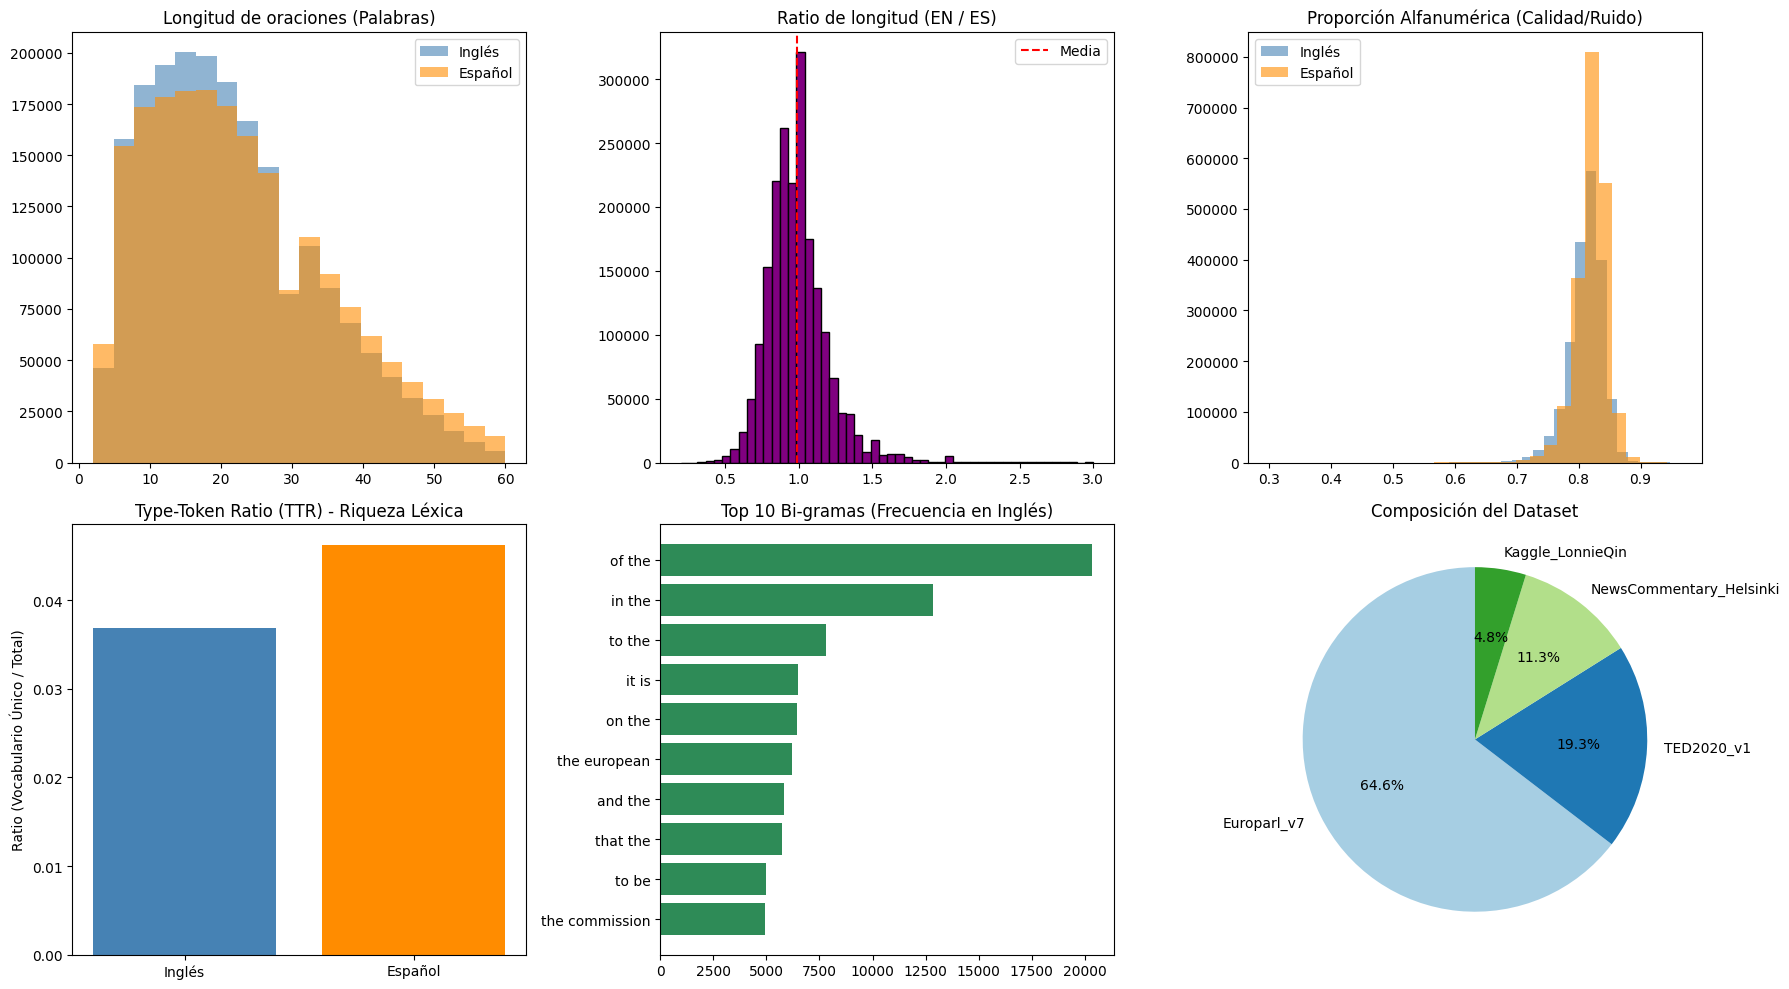


Iniciando exportación a Excel en dos hojas...
¡Proceso completado con éxito! El paquete ZIP y el Excel ya están listos para descargarse en: datos_traductor/run_20261003_033622/corpus_traductor_2M.zip


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import zipfile
import json
from collections import Counter
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

# Leer el archivo interno con metadatos generado en el paso previo
df_completo = pd.read_csv(RESULT_DIR / 'dataset_metadatos.csv', keep_default_na=False)

print(f"CSV GENERADO: {len(df_completo)} pares")
print("Calculando métricas avanzadas (esto puede tomar un par de minutos)...")

# Métricas de longitud y alineación
df_completo['ratio'] = df_completo['en_len'] / df_completo['es_len']

# Métricas de ruido y caracteres (Penaliza exceso de puntuación o código)
df_completo['en_alpha_ratio'] = df_completo['en'].str.count(r'[a-zA-Z0-9áéíóúÁÉÍÓÚñÑüÜ]') / df_completo['en'].str.len()
df_completo['es_alpha_ratio'] = df_completo['es'].str.count(r'[a-zA-Z0-9áéíóúÁÉÍÓÚñÑüÜ]') / df_completo['es'].str.len()

# Métricas de vocabulario (TTR Y N-GRAMAS)
df_sample = df_completo.sample(n=min(100000, len(df_completo)), random_state=42)

# Calculo de la riqueza léxica: Tokens Únicos y Tokens Totales (Type-Token Ratio)
def get_ttr(text_series):
    all_words = ' '.join(text_series).lower().split()
    return len(set(all_words)) / len(all_words) if all_words else 0

ttr_en = get_ttr(df_sample['en'])
ttr_es = get_ttr(df_sample['es'])

# Extrae las combinaciones de dos palabras más frecuentes para detectar sesgos
def get_top_bigrams(text_series, n=10):
    vec = CountVectorizer(ngram_range=(2, 2), max_features=1000).fit(text_series)
    bag_of_words = vec.transform(text_series)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

bigrams_en = get_top_bigrams(df_sample['en'])
fuentes_conteo = df_completo['source'].value_counts()


# Impresión de resultados numéricos
print("\n" + "="*50)
print("RESULTADOS NUMÉRICOS DEL EDA AVANZADO")
print("="*50)
print(f"1. Ratio de Longitud (EN/ES): Media = {df_completo['ratio'].mean():.3f}")
print(f"2. Calidad (Proporción Alfanumérica):")
print(f"   - Inglés : {df_completo['en_alpha_ratio'].mean()*100:.2f}%")
print(f"   - Español: {df_completo['es_alpha_ratio'].mean()*100:.2f}%")
print(f"3. Riqueza Léxica (Type-Token Ratio - TTR en 100k):")
print(f"   - Inglés : {ttr_en:.4f}")
print(f"   - Español: {ttr_es:.4f}")
print("4. Top 10 Bi-gramas más comunes (Inglés):")
for bg, freq in bigrams_en:
    print(f"   - '{bg}': {freq} veces")
print("5. Composición del Dataset:")
for fuente, cantidad in fuentes_conteo.items():
    print(f"   - {fuente}: {cantidad:,} pares ({(cantidad/len(df_completo))*100:.2f}%)")
print("="*50 + "\n")


# Gráficos del EDA
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Longitud de oraciones
axes[0, 0].hist(df_completo['en_len'], bins=20, alpha=0.6, color='steelblue', label='Inglés')
axes[0, 0].hist(df_completo['es_len'], bins=20, alpha=0.6, color='darkorange', label='Español')
axes[0, 0].set_title('Longitud de oraciones (Palabras)')
axes[0, 0].legend()

# Ratio de longitud (Alineación)
axes[0, 1].hist(df_completo['ratio'], bins=50, range=(0.2, 3.0), color='purple', edgecolor='black')
axes[0, 1].set_title('Ratio de longitud (EN / ES)')
axes[0, 1].axvline(df_completo['ratio'].mean(), color='red', linestyle='dashed', label='Media')
axes[0, 1].legend()

# Proporción de Caracteres Alfanuméricos (Ruido)
axes[0, 2].hist(df_completo['en_alpha_ratio'], bins=30, alpha=0.6, color='steelblue', label='Inglés')
axes[0, 2].hist(df_completo['es_alpha_ratio'], bins=30, alpha=0.6, color='darkorange', label='Español')
axes[0, 2].set_title('Proporción Alfanumérica (Calidad/Ruido)')
axes[0, 2].legend()

# Type-Token Ratio (TTR) - Riqueza Léxica
axes[1, 0].bar(['Inglés', 'Español'], [ttr_en, ttr_es], color=['steelblue', 'darkorange'])
axes[1, 0].set_title('Type-Token Ratio (TTR) - Riqueza Léxica')
axes[1, 0].set_ylabel('Ratio (Vocabulario Único / Total)')

# Top Bi-gramas (Inglés) - Repeticiones
bigram_labels, bigram_values = zip(*bigrams_en)
axes[1, 1].barh(bigram_labels[::-1], bigram_values[::-1], color='seagreen')
axes[1, 1].set_title('Top 10 Bi-gramas (Frecuencia en Inglés)')

# Composición de Fuentes
axes[1, 2].pie(fuentes_conteo, labels=fuentes_conteo.index, autopct='%1.1f%%', startangle=90, colors=plt.cm.Paired.colors)
axes[1, 2].set_title('Composición del Dataset')

fig.tight_layout()
ruta_graficos = RESULT_DIR / 'eda_avanzado.png'
fig.savefig(ruta_graficos, dpi=150)
plt.show()


# Exportación a Excel
print("\nIniciando exportación a Excel en dos hojas...")
df_limpio = df_completo[['en', 'es']]
ruta_excel = RESULT_DIR / 'pares_entrenamiento_2M.xlsx'

with pd.ExcelWriter(ruta_excel, engine='openpyxl') as writer:
    df_limpio.iloc[:1000000].to_excel(writer, index=False, sheet_name='Parte1')
    df_limpio.iloc[1000000:].to_excel(writer, index=False, sheet_name='Parte2')


# Empaquetado
ZIP_PATH = RESULT_DIR / 'corpus_traductor_2M.zip'
with zipfile.ZipFile(ZIP_PATH, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=3) as z:
    z.write(ruta_excel, arcname='pares_entrenamiento_2M.xlsx')
    z.write(ruta_graficos, arcname='eda_avanzado.png')
    z.write(RESULT_DIR / 'manifest.json', arcname='manifest.json')

print(f'¡Proceso completado con éxito! El paquete ZIP y el Excel ya están listos para descargarse en: {ZIP_PATH}')